# S03-03 — Classificação DORA de referência (C1) (#169)

Distribuição dos 500 repositórios da amostra final nas classes Elite, High, Medium e Low, por métrica e geral.

- Fonte: `entregas/s02-03-dataset-500-final/dataset-500.csv`, colunas `classe_*` (cortes do enunciado, contrato `lab03-enunciado-cortes-v2`; tabela em `docs/definicoes-operacionais.md`, seção 7).
- **Classe geral de referência:** mediana das notas (Low = 1, Medium = 2, High = 3, Elite = 4) de DF, lead time (b) por commit, CFR (a) por runs e tempo de recuperação, arredondada para baixo e ignorando métricas sem classe.
- As outras três combinações de variantes aparecem só como sensibilidade; a comparação sistemática de definições é a RQ07 (#173).
- A CFR (b) usa a heurística v1 (#161), ainda sem a validação da #162.
- Percentuais sobre os 500 repositórios; métricas sem valor aparecem como "Sem classe".
- Saídas: `tabelas/` (CSV) e `figuras/` (PNG). Reexecute com *Run All* a partir desta pasta.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from pipeline.classes_dora import ORDEM, REFERENCIA_GERAL, SEM_CLASSE, classe_geral, combinacoes_geral, distribuicao
from pipeline.descritiva import carregar_dataset

DATASET = RAIZ / "entregas" / "s02-03-dataset-500-final" / "dataset-500.csv"
FIGURAS, TABELAS = Path("figuras"), Path("tabelas")
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
})
TINTA = "#333333"
# Escala sequencial em cinza: Elite mais escura; sem classe em branco hachurado.
CORES = {"Elite": "#2b2b2b", "High": "#6b6b6b", "Medium": "#a8a8a8", "Low": "#dadada", SEM_CLASSE: "#ffffff"}
TEXTO = {"Elite": "#ffffff", "High": "#ffffff", "Medium": TINTA, "Low": TINTA, SEM_CLASSE: TINTA}

dados = carregar_dataset(DATASET)
dados["classe_geral"] = classe_geral(dados, list(REFERENCIA_GERAL.values()))
pd.options.display.float_format = "{:,.1f}".format
print(f"{len(dados)} repositórios")

500 repositórios


## Distribuição por métrica e geral

In [2]:
metricas = {
    "Frequência de deploy": "classe_deployment_frequency",
    "Lead time (a) por release": "classe_lead_time_a",
    "Lead time (b) por commit": "classe_lead_time_b",
    "CFR (a) runs": "classe_cfr_a",
    "CFR (b) releases corretivas": "classe_cfr_b",
    "Tempo de recuperação": "classe_tempo_recuperacao",
    "Geral: LT (b) + CFR (a)": "classe_geral",
}
tabela = distribuicao({rotulo: dados[coluna] for rotulo, coluna in metricas.items()})
tabela.to_csv(TABELAS / "c1_distribuicao_classes.csv", index=False)
tabela

,metrica,n,Elite,High,Medium,Low,Sem classe,Elite (%),High (%),Medium (%),Low (%),Sem classe (%)
0,Frequência de deploy,500,12,120,248,120,0,2.4,24.0,49.6,24.0,0.0
1,Lead time (a) por release,499,64,128,151,156,1,12.8,25.6,30.2,31.2,0.2
2,Lead time (b) por commit,499,56,135,149,159,1,11.2,27.0,29.8,31.8,0.2
3,CFR (a) runs,500,405,62,18,15,0,81.0,12.4,3.6,3.0,0.0
4,CFR (b) releases corretivas,498,94,91,68,245,2,18.8,18.2,13.6,49.0,0.4
5,Tempo de recuperação,469,113,305,43,8,31,22.6,61.0,8.6,1.6,6.2
6,Geral: LT (b) + CFR (a),500,28,220,226,26,0,5.6,44.0,45.2,5.2,0.0


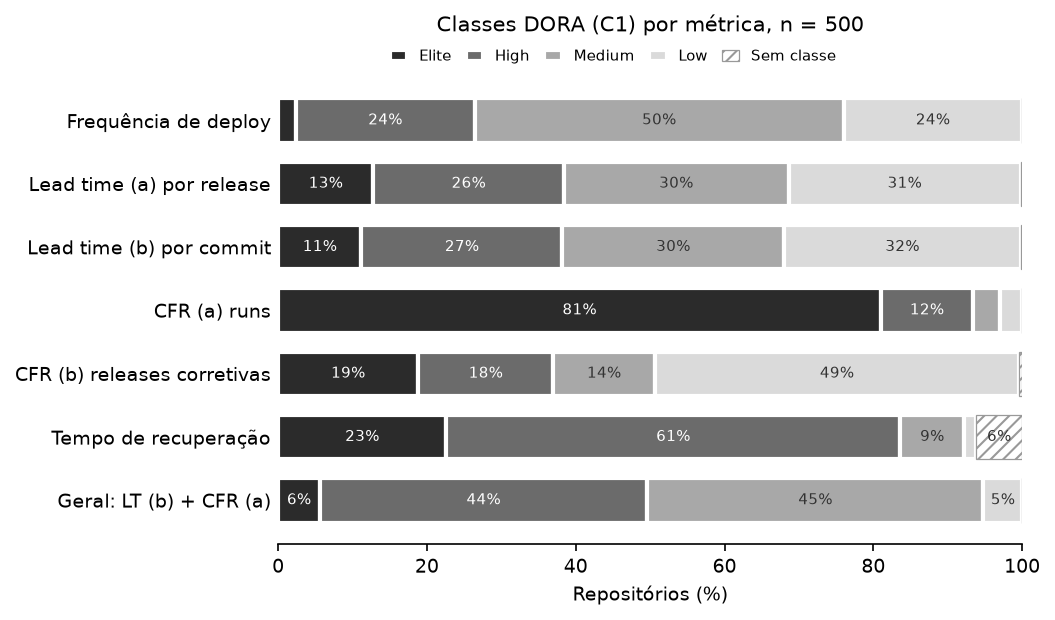

In [3]:
def barras_empilhadas(tabela, titulo, arquivo):
    rotulos = tabela["metrica"].tolist()[::-1]
    linhas = tabela.set_index("metrica").loc[rotulos]
    fig, ax = plt.subplots(figsize=(6.4, 0.42 * len(rotulos) + 1.1))
    esquerda = np.zeros(len(rotulos))
    for classe in ORDEM:
        valores = linhas[f"{classe} (%)"].to_numpy()
        if not valores.any():
            continue
        if classe == SEM_CLASSE:
            ax.barh(rotulos, valores, left=esquerda, color=CORES[classe], edgecolor="#999999", linewidth=0.6,
                    hatch="////", label=classe, height=0.7)
        else:
            ax.barh(rotulos, valores, left=esquerda, color=CORES[classe], edgecolor="white", linewidth=2,
                    label=classe, height=0.7)
        for y, (x, v) in enumerate(zip(esquerda, valores)):
            if v >= 5:
                ax.text(x + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=7, color=TEXTO[classe])
        esquerda += valores
    ax.set_xlim(0, 100)
    ax.set_xlabel("Repositórios (%)")
    ax.tick_params(axis="y", length=0)
    ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.45, 1.0), frameon=False, fontsize=7,
              handlelength=1.2, columnspacing=1.0)
    ax.set_title(titulo, fontsize=10, pad=22)
    fig.savefig(FIGURAS / arquivo)
    plt.show()


barras_empilhadas(tabela, f"Classes DORA (C1) por métrica, n = {len(dados)}", "c1_distribuicao_classes.png")

## Sensibilidade da classe geral às variantes

A mesma regra da classe geral com as quatro combinações de lead time e CFR. Só descritivo: a análise das combinações de definições é a RQ07 (#173).

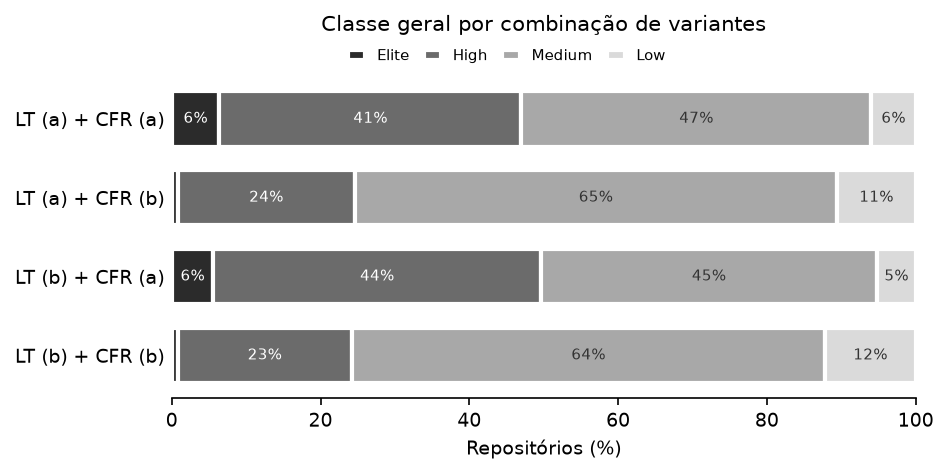

,metrica,n,Elite,High,Medium,Low,Sem classe,Elite (%),High (%),Medium (%),Low (%),Sem classe (%)
0,LT (a) + CFR (a),500,32,203,235,30,0,6.4,40.6,47.0,6.0,0.0
1,LT (a) + CFR (b),500,4,119,324,53,0,0.8,23.8,64.8,10.6,0.0
2,LT (b) + CFR (a),500,28,220,226,26,0,5.6,44.0,45.2,5.2,0.0
3,LT (b) + CFR (b),500,4,117,318,61,0,0.8,23.4,63.6,12.2,0.0


In [4]:
geral = {nome: classe_geral(dados, colunas) for nome, colunas in combinacoes_geral().items()}
sensibilidade = distribuicao(geral)
sensibilidade.to_csv(TABELAS / "c1_geral_combinacoes.csv", index=False)
barras_empilhadas(sensibilidade, "Classe geral por combinação de variantes", "c1_geral_combinacoes.png")
sensibilidade

In [5]:
referencia = geral["LT (b) + CFR (a)"]
mudancas = pd.Series({nome: int((serie != referencia).sum()) for nome, serie in geral.items()},
                     name="repositorios_com_classe_diferente_da_referencia").to_frame()
mudancas["percentual"] = 100 * mudancas.iloc[:, 0] / len(dados)
mudancas.to_csv(TABELAS / "c1_geral_mudancas.csv")
mudancas

,repositorios_com_classe_diferente_da_referencia,percentual
LT (a) + CFR (a),80,16.0
LT (a) + CFR (b),184,36.8
LT (b) + CFR (a),0,0.0
LT (b) + CFR (b),187,37.4


## Limitações

- As classes por métrica herdam as limitações de cada métrica (ver #167 e #168); ausências não recebem classe nem entram na classe geral.
- A classe geral com CFR (b) depende da heurística v1, ainda não validada (#162).
- A escolha de lead time (b) e CFR (a) para a referência é uma decisão do grupo; a sensibilidade acima mostra o efeito das alternativas.
- A amostra não é aleatória (ver o funil na metodologia).